# Industry Project: Credit-Card Fraud Detection (Production-Style)

> **Who is this notebook for?** Beginners who want to see how anomaly detection and imbalanced classification are used in a real bank or payments company.
> Every step is explained in plain English and the code is heavily commented.

---

### How this notebook is different from `01_anomaly_detection.ipynb`

| `01_anomaly_detection.ipynb` | This notebook |
|---|---|
| How Isolation Forest, LOF and autoencoders work | How a fraud team **combines** them into a working system |
| Random splits on toy data | **Time-based** split (train on the past, test on the future) |
| Accuracy-style metrics | **Alert budget**, precision@k, money saved |

### The business problem

You work at a payments company. About **0.5%** of card transactions are fraud.
A team of analysts can manually review **only ~1% of transactions per day**. Any fraud that isn't flagged is lost money.

**Your job:** score every transaction so the analysts review the *most suspicious* ones first.

### Why fraud is special
1. **Extreme imbalance**: 199 normal transactions for every fraud. Accuracy is useless (always saying "normal" = 99.5% accuracy).
2. **Labels arrive late**: you only learn a transaction was fraud when the customer complains, often weeks later. → we also build an **unsupervised** detector that needs no labels.
3. **Fraudsters adapt**: patterns change over time. → **time-based** validation, monitoring.
4. **Capacity is limited**: the real question is not "fraud yes/no", it's "which **top-N** to review".

### Table of Contents
1. Setup
2. Simulated transaction stream
3. Feature engineering: behaviour vs. the customer's own history
4. Time-based split
5. Unsupervised detector (no labels needed): Isolation Forest
6. Supervised detector: gradient boosting with class weights
7. Evaluate like a fraud team: precision@k and alert budget
8. Combine both detectors into one risk score
9. Money saved
10. Real-time scoring function with reason codes
11. Summary

---
## 1. Setup

In [1]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("fraud")

RANDOM_STATE = 42
REVIEW_BUDGET = 0.01          # analysts can review 1% of transactions

---
## 2. Simulated transaction stream

Real card data is confidential, so we simulate 90 days of transactions for 2,000 customers.
Each customer has **personal habits** (typical amount, home country, usual hours). We simulate three fraud patterns seen in real life:

| Pattern | What it looks like | Hard because... |
|---|---|---|
| Stolen card used abroad | burst of big purchases in another country | real customers also travel and shop abroad |
| Online fraud at home | one online purchase, normal country, daytime | looks almost like a normal online order |
| Card testing | several tiny charges ($0.50-$3) to check a stolen card works | amounts are *smaller* than normal |

We also add legitimate "weird" behaviour (night owls, holidays abroad, occasional big purchases), so the model can't cheat with one simple rule.

> Public real-world alternative: the Kaggle "Credit Card Fraud Detection" dataset (284k transactions, 0.17% fraud).

In [2]:
def simulate_transactions(n_customers: int = 2000, days: int = 90, seed: int = RANDOM_STATE) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    start = pd.Timestamp("2026-06-01")
    countries = ["US", "UK", "DE", "FR"]
    customers = pd.DataFrame({
        "customer_id": np.arange(n_customers),
        "typical_amount": rng.lognormal(3.5, 0.6, n_customers),          # each person spends differently
        "home_country": rng.choice(countries, n_customers, p=[0.6, 0.2, 0.1, 0.1]),
        "night_owl": rng.random(n_customers) < 0.10,                      # 10% of people shop late at night
    })

    # ---------- Normal behaviour (with realistic "weird but legit" cases) ----------
    rows = []
    for c in customers.itertuples():
        n_tx = rng.poisson(days * 0.8)                                    # ~0.8 transactions a day
        times = start + pd.to_timedelta(np.sort(rng.uniform(0, days, n_tx)), unit="D")
        on_trip = rng.random() < 0.08                                     # 8% travel abroad once
        trip_start = rng.uniform(0, days - 7)
        for t in times:
            day = (t - start).days
            hour = int(rng.normal(1, 2)) % 24 if c.night_owl else int(np.clip(rng.normal(14, 4), 0, 23))
            abroad = on_trip and trip_start <= day <= trip_start + 7
            amount = rng.lognormal(np.log(c.typical_amount), 0.5)
            if rng.random() < 0.02:                                       # occasional big legit purchase
                amount *= rng.uniform(3, 8)
            rows.append({"timestamp": t.replace(hour=hour), "customer_id": c.customer_id,
                         "amount": round(amount, 2),
                         "country": rng.choice(["ES", "IT", "BR", "US"]) if abroad else c.home_country,
                         "merchant_category": rng.choice(["grocery", "fuel", "restaurant", "online", "travel",
                                                          "electronics"], p=[0.33, 0.15, 0.25, 0.19, 0.05, 0.03]),
                         "is_fraud": 0})
    tx = pd.DataFrame(rows)

    # ---------- Fraud: three common patterns that OVERLAP with normal behaviour ----------
    n_fraud_target = int(len(tx) * 0.005)
    fraud_rows = []
    while len(fraud_rows) < n_fraud_target:
        v = int(rng.integers(n_customers))
        cust = customers.loc[v]
        t0 = start + pd.Timedelta(days=float(rng.uniform(0, days)))
        pattern = rng.choice(["stolen_card_abroad", "online_at_home", "card_testing"], p=[0.35, 0.45, 0.20])
        if pattern == "stolen_card_abroad":       # burst abroad, often at night, big amounts
            n, country = int(rng.integers(1, 4)), rng.choice(["BR", "NG", "RU", "US", "ES"])
            amounts = cust.typical_amount * rng.uniform(1.5, 8, n)
            hour = int(rng.choice([0, 1, 2, 3, 14, 18, 22]))
            mcc = ["electronics", "travel", "online"]
        elif pattern == "online_at_home":         # card details stolen online: home country, daytime, modest
            n, country = 1, cust.home_country
            amounts = cust.typical_amount * rng.uniform(1.0, 4, n)
            hour = int(np.clip(rng.normal(15, 4), 0, 23))
            mcc = ["online", "electronics"]
        else:                                     # "card testing": tiny charges to check the card works
            n, country = int(rng.integers(2, 5)), cust.home_country
            amounts = rng.uniform(0.5, 3.0, n)
            hour = int(rng.integers(0, 24))
            mcc = ["online"]
        for k in range(n):
            fraud_rows.append({"timestamp": (t0 + pd.Timedelta(minutes=int(rng.integers(1, 30)) * (k + 1))).replace(hour=hour),
                               "customer_id": v, "amount": round(float(amounts[k]), 2), "country": country,
                               "merchant_category": rng.choice(mcc), "is_fraud": 1})
    tx = pd.concat([tx, pd.DataFrame(fraud_rows)], ignore_index=True)
    return tx.sort_values("timestamp").reset_index(drop=True)


tx = simulate_transactions()
print(f"{len(tx):,} transactions | fraud rate {tx['is_fraud'].mean():.2%} | "
      f"{tx['timestamp'].min().date()} to {tx['timestamp'].max().date()}")
tx.head()

145,125 transactions | fraud rate 0.50% | 2026-06-01 to 2026-08-29


,timestamp,customer_id,amount,country,merchant_category,is_fraud
0,2026-06-01 00:00:33.574422672,269,24.18,US,fuel,0
1,2026-06-01 00:01:36.062329702,661,20.78,DE,electronics,0
2,2026-06-01 00:02:15.028600001,1602,71.31,US,online,0
3,2026-06-01 00:03:53.011117290,29,25.51,US,online,0
4,2026-06-01 00:04:15.355954176,60,12.30,UK,online,0


---
## 3. Feature engineering: behaviour vs. the customer's own history

A $900 purchase is normal for one person and very suspicious for another. The most powerful fraud features compare a transaction to **the same customer's past**.

⚠️ **Leakage danger:** these features must only use information available **at the moment of the transaction**. We therefore compute them with `shift()` and `rolling()` over **past** rows only. Using future data here is the #1 bug in fraud models: it gives amazing offline scores and terrible real-life results.

In [3]:
def build_fraud_features(data: pd.DataFrame) -> pd.DataFrame:
    """Point-in-time features: each row only uses that customer's EARLIER transactions."""
    df = data.sort_values(["customer_id", "timestamp"]).copy()
    g = df.groupby("customer_id")

    # How unusual is the amount compared with this customer's previous average?
    past_mean = g["amount"].transform(lambda s: s.shift().expanding().mean())
    df["amount_vs_history"] = (df["amount"] / past_mean).fillna(1.0)

    # Velocity: how many transactions did the card make in the previous hour?
    df["tx_last_hour"] = (df.set_index("timestamp").groupby("customer_id")["amount"]
                          .rolling("1h").count().values - 1)                 # -1 removes the current tx

    # Minutes since the previous transaction (bursts = suspicious)
    df["minutes_since_prev"] = g["timestamp"].diff().dt.total_seconds().div(60).fillna(24 * 60)

    # Is the country different from the customer's "home" country?
    # (approximated by the country of their FIRST ever transaction, which is known in the past)
    first_country = g["country"].transform("first")
    df["foreign_country"] = (df["country"] != first_country).astype(int)

    df["hour"] = df["timestamp"].dt.hour
    df["is_night"] = df["hour"].isin([0, 1, 2, 3, 4, 5, 23]).astype(int)
    df["log_amount"] = np.log1p(df["amount"])
    df = pd.get_dummies(df, columns=["merchant_category"], prefix="mcc", dtype=int)   # one-hot encode
    return df.sort_values("timestamp").reset_index(drop=True)


features = build_fraud_features(tx)
FEATURES = ["log_amount", "amount_vs_history", "tx_last_hour", "minutes_since_prev",
            "foreign_country", "hour", "is_night"] + [c for c in features.columns if c.startswith("mcc_")]
features[FEATURES + ["is_fraud"]].groupby("is_fraud").mean().T.round(2)

is_fraud,0,1
log_amount,3.54,3.33
amount_vs_history,1.03,1.91
tx_last_hour,0.06,0.69
minutes_since_prev,1758.75,1029.80
foreign_country,0.01,0.32
hour,12.63,11.48
is_night,0.12,0.29
mcc_electronics,0.03,0.27
mcc_fuel,0.15,0.00
mcc_grocery,0.33,0.00


The table shows **average feature values for normal (0) vs. fraud (1)** transactions. Fraud has higher `amount_vs_history`, more `tx_last_hour`, and more night/foreign activity on average, so the features carry signal. But averages hide overlap: many fraud transactions look perfectly normal on every single feature.

---
## 4. Time-based split (with a label-delay gap)

In fraud (and most real-world problems) you train on the **past** and predict the **future**. A random split would let the model "peek" at future fraud patterns.

There is one more industry detail: fraud labels arrive **late** (customers report fraud days or weeks later). So on the day you retrain, the labels for the most recent days are **not yet known**. The *Fraud Detection Handbook* (Le Borgne et al., see resources below) therefore leaves a **delay gap** between training and test:

- **Train**: days 1-53
- **Gap**: days 54-60 (labels not trustworthy yet, so not used)
- **Test**: days 61-90 (simulates "deploy the model and watch it for a month")

In [4]:
first_day = features["timestamp"].min().normalize()
train_end = first_day + pd.Timedelta(days=53)          # end of training period
test_start = first_day + pd.Timedelta(days=60)         # 7-day delay gap in between
train = features[features["timestamp"] < train_end]
test = features[features["timestamp"] >= test_start]
X_train, y_train = train[FEATURES], train["is_fraud"]
X_test, y_test = test[FEATURES], test["is_fraud"]
print(f"Train: {len(train):,} tx ({y_train.sum()} fraud) | Test: {len(test):,} tx ({y_test.sum()} fraud)")

Train: 85,418 tx (396 fraud) | Test: 48,353 tx (270 fraud)


---
## 5. Unsupervised detector (no labels needed): Isolation Forest

Remember: fraud labels arrive **late**. On day one of a new product you may have **zero** labels.
**Isolation Forest** learns what "normal" looks like and flags transactions that are easy to isolate (rare combinations of values).
It is trained **without** `y`; we only use labels afterwards to *measure* how well it worked.

In [5]:
iso = IsolationForest(n_estimators=300, contamination="auto", random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(X_train)                                     # no labels used!
iso_score_test = -iso.score_samples(X_test)          # flip sign: higher = more anomalous

print(f"Isolation Forest | ROC-AUC {roc_auc_score(y_test, iso_score_test):.3f} | "
      f"PR-AUC {average_precision_score(y_test, iso_score_test):.3f} (random would be {y_test.mean():.3f})")

Isolation Forest | ROC-AUC 0.911 | PR-AUC 0.332 (random would be 0.006)


---
## 6. Supervised detector: gradient boosting with class weights

Once we have labels from the past, a supervised model is usually much stronger.
With 0.5% fraud, the model would mostly ignore the fraud class, so we give fraud examples a **higher weight** (`class_weight="balanced"`).

In [6]:
gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight="balanced",
                                     random_state=RANDOM_STATE)
gbm.fit(X_train, y_train)
gbm_score_test = gbm.predict_proba(X_test)[:, 1]

print(f"Gradient Boosting | ROC-AUC {roc_auc_score(y_test, gbm_score_test):.3f} | "
      f"PR-AUC {average_precision_score(y_test, gbm_score_test):.3f}")

Gradient Boosting | ROC-AUC 0.980 | PR-AUC 0.702


**Why we prefer PR-AUC over ROC-AUC here:** with 0.5% fraud, ROC-AUC can look excellent (0.95+) even when most alerts are false alarms, because it is dominated by the huge number of easy normal transactions. PR-AUC focuses on the fraud class. The *Fraud Detection Handbook* also found that ROC-AUC tends to pick over-fitted models.

> 🚩 **Red flag rule:** if a real fraud model ever scores a ROC-AUC of ~1.00, don't celebrate, look for **leakage** (e.g. a feature computed with future data, or a column that is only filled in after an investigation).

---
## 7. Evaluate like a fraud team: precision@k and alert budget

Analysts review the **top 1%** highest-scoring transactions. So the questions are:
- **Precision@k**: of the transactions we sent to analysts, what fraction were really fraud? (Low precision = wasted analyst time.)
- **Recall@k**: of all fraud, what fraction did we catch within the budget?

In [7]:
def budget_metrics(y_true: pd.Series, scores: np.ndarray, budget: float = REVIEW_BUDGET) -> dict:
    """Metrics when only the top `budget` share of transactions can be reviewed."""
    k = max(1, int(len(scores) * budget))
    top_k = np.argsort(scores)[::-1][:k]              # indices of the k highest scores
    caught = y_true.values[top_k].sum()
    return {"reviewed": k, "fraud_caught": int(caught),
            "precision@k": round(caught / k, 3), "recall@k": round(caught / y_true.sum(), 3)}


pd.DataFrame({
    "Isolation Forest (no labels)": budget_metrics(y_test, iso_score_test),
    "Gradient Boosting (labels)": budget_metrics(y_test, gbm_score_test),
}).T

,reviewed,fraud_caught,precision@k,recall@k
Isolation Forest (no labels),483.0,103.0,0.213,0.381
Gradient Boosting (labels),483.0,200.0,0.414,0.741


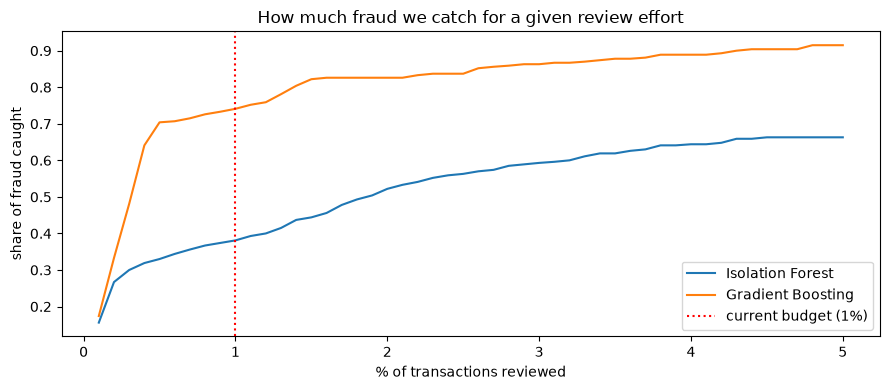

In [8]:
# Recall as a function of review budget: helps managers decide how many analysts to hire
budgets = np.linspace(0.001, 0.05, 50)
fig, ax = plt.subplots(figsize=(9, 4))
for name, s in [("Isolation Forest", iso_score_test), ("Gradient Boosting", gbm_score_test)]:
    ax.plot(budgets * 100, [budget_metrics(y_test, s, b)["recall@k"] for b in budgets], label=name)
ax.axvline(REVIEW_BUDGET * 100, color="red", ls=":", label="current budget (1%)")
ax.set_xlabel("% of transactions reviewed"); ax.set_ylabel("share of fraud caught")
ax.set_title("How much fraud we catch for a given review effort"); ax.legend()
plt.tight_layout(); plt.show()

---
## 8. Combine both detectors into one risk score

Production fraud systems are almost always **ensembles**:
- the **supervised** model is great at **known** fraud patterns,
- the **unsupervised** model can catch **new** patterns the labels have never shown.

A simple, robust way to combine scores on different scales is to convert each to a **rank percentile** (0 to 1) and take a weighted average.

In [9]:
def to_percentile(scores: np.ndarray) -> np.ndarray:
    """Convert any score to 0-1 by its rank. Makes different models comparable."""
    return pd.Series(scores).rank(pct=True).values


combined_score = 0.8 * to_percentile(gbm_score_test) + 0.2 * to_percentile(iso_score_test)
pd.DataFrame({
    "Isolation Forest": budget_metrics(y_test, iso_score_test),
    "Gradient Boosting": budget_metrics(y_test, gbm_score_test),
    "Combined (80/20)": budget_metrics(y_test, combined_score),
}).T

,reviewed,fraud_caught,precision@k,recall@k
Isolation Forest,483.0,103.0,0.213,0.381
Gradient Boosting,483.0,200.0,0.414,0.741
Combined (80/20),483.0,195.0,0.404,0.722


**Be honest about results.** On this test month, the combined score is about as good as gradient boosting alone (sometimes slightly worse). That's expected: the test month only contains fraud patterns the supervised model already learned. The unsupervised part is an **insurance policy** for *new* attack patterns that have no labels yet, which is why fraud teams usually keep it with a small weight and monitor it separately. Never add complexity just because "ensembles are better"; measure it.

---
## 9. Money saved
Translate the model into the number executives care about. We assume each fraud we catch avoids the lost amount, and each review costs $3 of analyst time.

In [10]:
REVIEW_COST = 3.0
k = int(len(X_test) * REVIEW_BUDGET)
top_k = np.argsort(gbm_score_test)[::-1][:k]
fraud_amounts = test["amount"].values * y_test.values

saved = fraud_amounts[top_k].sum()
total_fraud = fraud_amounts.sum()
print(f"Total fraud in test month : ${total_fraud:,.0f}")
print(f"Fraud amount caught       : ${saved:,.0f} ({saved / total_fraud:.0%})")
print(f"Analyst cost ({k} reviews) : ${k * REVIEW_COST:,.0f}")
print(f"Net benefit               : ${saved - k * REVIEW_COST:,.0f}")

Total fraud in test month : $20,855
Fraud amount caught       : $15,140 (73%)
Analyst cost (483 reviews) : $1,449
Net benefit               : $13,691


---
## 10. Real-time scoring function with reason codes

When a card is swiped, the system has ~100 milliseconds to decide. The function must also explain **why** a transaction was flagged ("reason codes"). Regulators often require this, and analysts need it to work fast.

In [11]:
import time

REASON_RULES = [  # (feature, condition, human-readable reason)
    ("amount_vs_history", lambda v: v > 3, "Amount is {v:.1f}x the customer's usual spend"),
    ("tx_last_hour", lambda v: v >= 2, "{v:.0f} other transactions in the last hour"),
    ("foreign_country", lambda v: v == 1, "Transaction outside the home country"),
    ("is_night", lambda v: v == 1, "Unusual time of day"),
    ("log_amount", lambda v: v < np.log1p(3), "Tiny amount, typical of 'card testing'"),
    ("mcc_electronics", lambda v: v == 1, "High-risk merchant category (electronics)"),
]


def score_transaction(feature_row: dict, threshold: float = 0.5) -> dict:
    """Score ONE transaction (already converted to features) and explain the decision."""
    start = time.perf_counter()
    frame = pd.DataFrame([feature_row])[FEATURES]
    probability = float(gbm.predict_proba(frame)[0, 1])
    reasons = [msg.format(v=feature_row[f]) for f, rule, msg in REASON_RULES if rule(feature_row[f])]
    return {"fraud_probability": round(probability, 3),
            "decision": "HOLD for review" if probability >= threshold else "APPROVE",
            "reasons": reasons or ["No risk signals"],
            "latency_ms": round((time.perf_counter() - start) * 1000, 1)}


suspicious = test.iloc[int(np.argmax(gbm_score_test))][FEATURES].to_dict()   # the highest-risk test transaction
normal = test[test["is_fraud"] == 0].iloc[0][FEATURES].to_dict()
print("Suspicious:", score_transaction(suspicious))
print("Normal    :", score_transaction(normal))

Suspicious: {'fraud_probability': 0.954, 'decision': 'HOLD for review', 'reasons': ["Tiny amount, typical of 'card testing'"], 'latency_ms': 2.5}
Normal    : {'fraud_probability': 0.045, 'decision': 'APPROVE', 'reasons': ['Unusual time of day'], 'latency_ms': 2.8}


---
## 11. Summary

| Fraud-industry practice | What we did |
|---|---|
| Point-in-time features | Only past transactions per customer (`shift`, `rolling`) |
| Time-based validation | Train on 60 days, test on the following 30 |
| Works without labels | Isolation Forest baseline |
| Handles extreme imbalance | `class_weight="balanced"`, PR-AUC instead of accuracy |
| Business metrics | precision@k, recall@k under an alert budget, money saved |
| Ensembles | Rank-averaged supervised + unsupervised scores |
| Explainable decisions | Reason codes in the real-time scorer |

### Practice exercises
1. Change `REVIEW_BUDGET` to 0.5% and 2%. How do recall and net benefit change?
2. Add a feature `amount_vs_history_max` (amount / customer's largest past amount).
3. Try `sklearn.neighbors.LocalOutlierFactor(novelty=True)` as the unsupervised detector.

### Things real fraud teams also deal with
- **Feedback loop:** analysts only label the transactions the model flagged, so the training labels are biased towards what the old model already caught.
- **Card-level alerts:** teams usually alert on the **card** (max score per card per day), not on each transaction, and skip cards already blocked.
- **Merchant/terminal risk features:** e.g. "fraud rate at this shop over the last 7 days" (computed with the label delay in mind).

### Resources
- *Reproducible Machine Learning for Credit Card Fraud Detection, Practical Handbook* (Le Borgne et al.): https://fraud-detection-handbook.github.io/fraud-detection-handbook/
- Kaggle dataset "Credit Card Fraud Detection" (ULB): https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

### Related notebooks
- Algorithms: `01_anomaly_detection.ipynb`
- Imbalanced data techniques (SMOTE etc.): `../05_feature_engineering/02_imbalanced_data.ipynb`
- Streaming / drift: `../12_online_learning/01_online_learning.ipynb`